# Assignment 1: Data Profiling (EDA) Report

**Course:** TTTC3213 Data Engineering

**Topic:** Data Profiling, Anomaly Diagnosis, and Quality Remediation on HR Analytics Data

### Team Members

1. Maira Fareeha binti Mohd Fairuz (A211841)
2. Nur Aida Najihah binti Abdul Samad (A212235)
3. Fateen Jazmeena binti Faizal Hamdy (A212314)
4. Nur Sarah Diyana binti Md Sayuti (A212318)

### Instructions to Run

1. Open this notebook in Google Colab or JupyterLab.
2. Ensure the dataset file `aug_train.csv` is uploaded to the runtime directory.
3. Run all cells sequentially from top to bottom (`Runtime` -> `Run all` or `Ctrl + F9`).

## **1. Scenario**

A Big Data and Data Science company provides professional training courses and seeks to determine whether enrolled candidates intend to join the firm or seek external job opportunities. This dataset fits the required messy conditions because voluntary, self-reported candidate profiles have generated extensive missing values, extreme outliers in training hours, inconsistent career formats, and demographic representation risks. Through data profiling, we want to answer: (1) what data quality flaws compromise the validity of candidate profiles, and (2) how do missingness patterns and demographic imbalances introduce bias into hiring evaluations?

## **2. Data Source**

* **Origin:** Kaggle — *HR Analytics: Job Change of Data Scientists* dataset.
* **Dataset URL:** [https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists)
* **How Obtained:** Downloaded directly as a CSV archive (`aug_train.csv`) from Kaggle and loaded into Pandas via Google Colab runtime session storage. The dataset is provided under the CC0: Public Domain license for educational, research, and analytical use.

## **3. Data Profiling and Issue Handling**

### **Missing Values**

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

df_raw = pd.read_csv('aug_train.csv')

In [ ]:
# 1. Inspect Missing Values in Raw Data
missing_count = df_raw.isnull().sum()
missing_percent = (missing_count / len(df_raw)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent.round(2)
})
missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("--- Initial Missing Value Audit ---")
display(missing_summary)

# 2. Make an explicit working copy
df_clean = df_raw.copy()

# 3. Apply Remediation: Flagging High-Missingness Columns (>10%)
flag_unknown_cols = ['company_type', 'company_size', 'major_discipline']
for col in flag_unknown_cols:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Sensitive demographic field flagged separately
df_clean['gender'] = df_clean['gender'].fillna('Not Disclosed')

# 4. Apply Remediation: Mode Imputing Low-Missingness Columns (<3%)
mode_impute_cols = ['education_level', 'last_new_job', 'enrolled_university', 'experience']
for col in mode_impute_cols:
    mode_value = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_value)

# 5. Verification
remaining_nulls = df_clean.isnull().sum().sum()
print(f"\nTotal null values remaining in cleaned dataset: {remaining_nulls}")

--- Initial Missing Value Audit ---


,Missing Count,Percentage (%)
company_type,6140,32.05
company_size,5938,30.99
gender,4508,23.53
major_discipline,2813,14.68
education_level,460,2.40
last_new_job,423,2.21
enrolled_university,386,2.01
experience,65,0.34



Total null values remaining in cleaned dataset: 0


#### Where and How Much
Out of the 14 columns and 19,158 records in `aug_train.csv`, 8 features contain missing values. Non-response is heavily concentrated in optional career and demographic fields:

| Feature Name | Missing Count | Percentage (%) | Proposed Action | Justification / Reasoning |
| :--- | :---: | :---: | :---: | :--- |
| `company_type` | 6,140 | 32.05% | **Flag** as `'Unknown'` | Dropping these records would delete nearly a third of the dataset. Imputing with the mode (`Pvt Ltd`) would fabricate employer structure for unemployed individuals, freelancers, or students. |
| `company_size` | 5,938 | 30.99% | **Flag** as `'Unknown'` | Missingness represents non-disclosure or non-applicable employer tiers (e.g., self-employed). Flagging retains the records without distorting enterprise-scale distributions. |
| `gender` | 4,508 | 23.53% | **Flag** as `'Not Disclosed'` | Sensitive demographic feature. Imputing with the majority class (`Male`, ~69%) would artificially exacerbate algorithmic bias. Flagging respects voluntary non-disclosure. |
| `major_discipline` | 2,813 | 14.68% | **Flag** as `'Unknown'` | Candidates omitting a major often hold non-traditional backgrounds (e.g., high school education or unaccredited bootcamps). Forcing a `'STEM'` mode imputation introduces credential distortion. |
| `education_level` | 460 | 2.40% | **Impute** with Mode (`'Graduate'`) | Missingness is minimal (< 2.5%). Mode imputation is applied as a practical baseline remediation strategy, though it may alter baseline distributions. |
| `last_new_job` | 423 | 2.21% | **Impute** with Mode (`'1'`) | Negligible missingness (< 2.5%). Used to fill missing entries under a simplistic baseline assumption. |
| `enrolled_university` | 386 | 2.01% | **Impute** with Mode (`'no_enrollment'`) | Minimal missingness (< 2.5%). Imputed using the most frequent category as a baseline simplification. |
| `experience` | 65 | 0.34% | **Impute** with Mode (`'>20'`) | Negligible missingness (< 0.5%). Preserves row completion, though imputing the majority value can introduce bias toward high experience. |

#### Strategy Summary

* **No Listwise Deletion (Dropping Rows):** Complete-case analysis (dropping any row with at least one missing entry) would discard **10,203 rows (53.26% of the dataset)**, introducing severe data loss and reducing the available sample size for further analysis.

* **Informative Flagging for High Missingness (>10%):** Missing values in professional background fields may be related to candidates' employment circumstances. Therefore, missing cells are converted into explicit categories such as `'Unknown'` and `'Not Disclosed'` to preserve the information that the data was not provided. However, the missingness mechanism cannot be confirmed as MNAR from the dataset alone.

* **Mode Imputation for Low Missingness (<3%):** Mode imputation is applied to categorical variables with relatively low missing percentages. This provides a practical way to fill missing values while retaining the records. However, the dataset alone cannot confirm whether these missing values are Missing at Random (MAR).

### **Outliers**

Outlier Detection Method

We use Interquartile Range (IQR) method to identify outliers. IQR calculates the lower and upper boundaries. Values below the lower bound or above the upper bound are classified as potential outliers.

In [ ]:
# Method: Interquartile Range (IQR)
# Select numerical variable
column = 'training_hours'

# Calculate Q1, Q3 and IQR
Q1 = df_raw[column].quantile(0.25)
Q3 = df_raw[column].quantile(0.75)
IQR = Q3 - Q1

# Calculate lower and upper boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Identify outliers
outliers = df_raw[
    (df_raw[column] < lower_bound) |
    (df_raw[column] > upper_bound)
]

# Display results
print("OUTLIER DETECTION USING IQR")
print("--------------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Records:", len(df_raw))
print("Number of Outliers:", len(outliers))
print("Percentage of Outliers:",
      round((len(outliers) / len(df_raw)) * 100, 2), "%")

# Display some outlier records
print("\nSample Outlier Records:")
display(outliers[['enrollee_id', 'training_hours']].head(10))

OUTLIER DETECTION USING IQR
--------------------------------
Q1: 23.0
Q3: 88.0
IQR: 65.0
Lower Bound: -74.5
Upper Bound: 185.5
Total Records: 19158
Number of Outliers: 984
Percentage of Outliers: 5.14 %

Sample Outlier Records:


,enrollee_id,training_hours
35,4866,206
69,4830,228
89,32401,332
110,4789,210
119,14199,260
133,32776,290
161,13333,326
164,4064,198
176,3024,246
210,7672,202


In [ ]:
# Create an outlier indicator
df_raw['training_hours_outlier'] = (
    (df_raw['training_hours'] < lower_bound) |
    (df_raw['training_hours'] > upper_bound)
)
df_clean['training_hours_outlier'] = df_raw['training_hours_outlier']

# Count normal and outlier records
print(df_raw['training_hours_outlier'].value_counts())

# Display final result
print("\nOutlier Handling Summary:")
print("Dataset shape after adding outlier flag:", df_raw.shape)
print("Outliers retained:", df_raw['training_hours_outlier'].sum())

training_hours_outlier
False    18174
True       984
Name: count, dtype: int64

Outlier Handling Summary:
Dataset shape after adding outlier flag: (19158, 15)
Outliers retained: 984


For this dataset, the outliers are **kept** instead of removing them.

Reasons:
1. High training hours may represent genuine candidates who completed more training.
2. Removing these records could result in losing useful candidate information.
3. The values may be extreme but are not necessarily incorrect or invalid.
4. Keeping the original values preserves the dataset for further analysis.

### **Other Quality Issues**

**Purpose:** We checked the data (after handling missing values) for four quality issues and fixed the ones we could fix safely.

| Check | Why it matters |
|---|---|
| Duplicates | Repeated records count the same person twice |
| Data types | The target column is stored as float64 even though it has binary values (0 and 1), so it should be converted to an integer type. The enrollee_id column is already stored as an integer. |
| Inconsistent formats | Labels that mean the same thing but look different break sorting and grouping |
| Invalid values | Values outside a valid range (e.g. negative training hours) are probably entry mistakes |

In [ ]:
assert 'df_raw' in globals() and 'df_clean' in globals(), "Run the missing-value cells first."

n = len(df_clean)

# ---- 1. Duplicates ----
feature_cols = [c for c in df_clean.columns if c != 'enrollee_id']   # reused by the Fixes cell
dup_counts = {
    'Duplicate enrollee_id':            int(df_clean['enrollee_id'].duplicated().sum()),
    'Fully identical rows (incl. ID)':  int(df_clean.duplicated().sum()),
    'Identical profiles (ID ignored)':  int(df_clean.duplicated(subset=feature_cols).sum()),
}
duplicate_summary = pd.DataFrame({
    'Affected Count': dup_counts.values(),
    'Percentage (%)': [round(v / n * 100, 2) for v in dup_counts.values()]
}, index=list(dup_counts.keys()))

print("--- Duplicate Audit ---")
display(duplicate_summary)

# ---- 2. Data types ----
dtype_summary = pd.DataFrame({
    'Data Type': df_clean.dtypes.astype(str),
    'Unique Values': df_clean.nunique(),
    'Sample Values': [', '.join(map(str, df_clean[c].dropna().unique()[:3])) for c in df_clean.columns]
})

print("\n--- Data Type Audit ---")
display(dtype_summary)

# ---- 3. Inconsistent formats ----
text_cols = df_clean.select_dtypes(include='object').columns
ws_total = sum(int((df_clean[c].astype(str) != df_clean[c].astype(str).str.strip()).sum())
               for c in text_cols)
bad_city = int((~df_clean['city'].astype(str).str.match(r'^city_\d+$')).sum())

format_rows = {
    "company_size: inconsistent label ('10/49')":
        (df_raw['company_size'].nunique(), int((df_raw['company_size'] == '10/49').sum())),
    "experience: symbolic labels ('<1', '>20')":
        (df_raw['experience'].nunique(), int(df_raw['experience'].isin(['<1', '>20']).sum())),
    "last_new_job: symbolic labels ('never', '>4')":
        (df_raw['last_new_job'].nunique(), int(df_raw['last_new_job'].isin(['never', '>4']).sum())),
    "city: not matching 'city_<number>'":
        (df_clean['city'].nunique(), bad_city),
    "Leading/trailing whitespace in text columns":
        ('n/a', ws_total),
}
format_summary = pd.DataFrame({
    'Distinct Labels': [v[0] for v in format_rows.values()],
    'Affected Count':  [v[1] for v in format_rows.values()],
    'Percentage (%)':  [round(v[1] / n * 100, 2) for v in format_rows.values()]
}, index=list(format_rows.keys())).sort_values(by='Affected Count', ascending=False)

print("\n--- Format Audit ---")
display(format_summary)

# ---- 4. Invalid values (rule-based, read-only) ----
rules = {
    'target not in {0,1}'                  : ~pd.to_numeric(df_clean['target'], errors='coerce').isin([0, 1]),
    'city_development_index outside [0,1]' : ~df_clean['city_development_index'].between(0, 1),
    'training_hours negative'              : df_clean['training_hours'] < 0,
    'gender not in expected categories'    : ~df_clean['gender'].isin(['Male', 'Female', 'Other', 'Not Disclosed']),
}
invalid_summary = pd.DataFrame({
    'Violations':     [int(m.sum()) for m in rules.values()],
    'Percentage (%)': [round(m.sum() / n * 100, 2) for m in rules.values()]
}, index=list(rules.keys()))

print("\n--- Invalid Value Audit ---")
display(invalid_summary)

--- Duplicate Audit ---


,Affected Count,Percentage (%)
Duplicate enrollee_id,0,0.00
Fully identical rows (incl. ID),0,0.00
Identical profiles (ID ignored),50,0.26



--- Data Type Audit ---


,Data Type,Unique Values,Sample Values
enrollee_id,int64,19158,"8949, 29725, 11561"
city,object,123,"city_103, city_40, city_21"
city_development_index,float64,93,"0.92, 0.7759999999999999, 0.624"
gender,object,4,"Male, Not Disclosed, Female"
relevent_experience,object,2,"Has relevent experience, No relevent experience"
enrolled_university,object,3,"no_enrollment, Full time course, Part time course"
education_level,object,5,"Graduate, Masters, High School"
major_discipline,object,7,"STEM, Business Degree, Unknown"
experience,object,22,">20, 15, 5"
company_size,object,9,"Unknown, 50-99, <10"



--- Format Audit ---


,Distinct Labels,Affected Count,Percentage (%)
"last_new_job: symbolic labels ('never', '>4')",6,5742,29.97
"experience: symbolic labels ('<1', '>20')",22,3808,19.88
company_size: inconsistent label ('10/49'),8,1471,7.68
city: not matching 'city_<number>',123,0,0.00
Leading/trailing whitespace in text columns,n/a,0,0.00



--- Invalid Value Audit ---


,Violations,Percentage (%)
"target not in {0,1}",0,0.0
"city_development_index outside [0,1]",0,0.0
training_hours negative,0,0.0
gender not in expected categories,0,0.0


### **Findings from the audit (19,158 rows, 15 columns at the audit stage)**

**Duplicates**
- No duplicate enrollee IDs or completely identical records were detected. However, 50 pairs of identical profiles were identified when enrollee IDs were excluded. These records were retained because identical profile attributes do not necessarily indicate duplicate individuals, and there is insufficient evidence to determine whether they represent the same person.

**Data types**
- `target` is stored as a decimal (`float64`: 1.0 / 0.0) but it is a 0/1 label, so it should be an integer.
- All other columns already have the right type.

**Inconsistent formats**
| Column | Issue | Rows affected | % of data |
|---|---|---|---|
| `last_new_job` | Words and symbols (`never`, `>4`) mixed with numbers | 5,742 | 29.97% |
| `experience` | Symbols (`<1`, `>20`) mixed with numbers | 3,808 | 19.88% |
| `company_size` | `10/49` uses a slash while the other ranges use a hyphen | 1,471 | 7.68% |

- The `experience` count is 3,808 in the raw data. It becomes 3,873 in the fixes below because 65 missing values were filled with `>20` earlier.
- `city` labels all follow the `city_<number>` pattern, and none of the 10 text columns have extra spaces.

**Invalid values**
- None found. `target` is only 0 or 1, `city_development_index` is between 0 and 1, `training_hours` is never negative, and `gender` only has the four expected categories.

**Summary:** The main problems are formatting, not duplicates or invalid values. We need to standardise `last_new_job`, `experience` and `company_size`, and change `target` to an integer.

**Decisions**
- **Duplicates:** Dropped rows only if `enrollee_id` repeats. None found (0). We retained the 100 records involved in the 50 identical-profile pairs because matching profile attributes alone do not establish that they are duplicate individuals.
- **Data types:** Changed `target` from float to integer because it is a 0/1 label.
- **Whitespace:** None found, so nothing to strip.
- **`company_size`:** Changed `10/49` to `10-49` (1,471 rows) in a new column, `company_size_std`, so all ranges use the same style. The original column is kept.
- **`experience` and `last_new_job`:** Converted to numbers in new columns (`experience_years`, `last_new_job_years`). `<1` and `never` became 0. `>20` became 21 and `>4` became 5 (the lowest value in each range), so these groups look slightly smaller than they really are.
- **Invalid values:** We would drop rows that break a rule, because we cannot guess the correct value. None found (0), so no rows were dropped.

In [ ]:
fix_log = []

# ---- Fix 1: Duplicates ----
# Drop only if the unique ID itself repeats (a true duplicate record).
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='enrollee_id', keep='first')
fix_log.append(('Duplicate enrollee_id', 'Dropped repeated IDs (kept first)', before - len(df_clean), 'rows'))
profile_dups_kept = int(df_clean.duplicated(subset=feature_cols).sum())
fix_log.append(('Identical profiles (distinct IDs)', 'Kept: different people can share a profile', profile_dups_kept, 'rows'))

# ---- Fix 2: Data types ----
target_dtype_before = str(df_clean['target'].dtype)
df_clean['enrollee_id'] = df_clean['enrollee_id'].astype(int)
df_clean['target'] = pd.to_numeric(df_clean['target'], errors='coerce')

# ---- Fix 3: Whitespace in text columns ----
text_cols_fix = df_clean.select_dtypes(include='object').columns
ws_rows = sum(int((df_clean[c].astype(str) != df_clean[c].astype(str).str.strip()).sum())
              for c in text_cols_fix)
for c in text_cols_fix:
    df_clean[c] = df_clean[c].astype(str).str.strip()
fix_log.append(('Leading/trailing whitespace', 'Stripped from text columns', ws_rows, 'cells'))

# ---- Fix 4: company_size label standardisation ('10/49' -> '10-49') ----
size_order = ['<10', '10-49', '50-99', '100-500', '500-999',
              '1000-4999', '5000-9999', '10000+', 'Unknown']
size_fixed = int((df_clean['company_size'] == '10/49').sum())
df_clean['company_size_std'] = df_clean['company_size'].str.replace('/', '-', regex=False)
unexpected = set(df_clean['company_size_std']) - set(size_order)
print("Unexpected company_size labels after fix:", unexpected or "none")
fix_log.append(("company_size ('10/49')", "Relabelled to '10-49' in company_size_std", size_fixed, 'rows'))

# ---- Fix 5: experience / last_new_job symbols -> numeric (new columns) ----
def parse_experience(v):
    v = str(v)
    if v == '<1':  return 0     # less than a year -> 0
    if v == '>20': return 21    # lower bound of open-ended '>20'
    return int(v)

def parse_last_new_job(v):
    v = str(v)
    if v == 'never': return 0
    if v == '>4':    return 5   # lower bound of open-ended '>4'
    return int(v)

exp_symbolic = int(df_clean['experience'].isin(['<1', '>20']).sum())
job_symbolic = int(df_clean['last_new_job'].isin(['never', '>4']).sum())
df_clean['experience_years']   = df_clean['experience'].apply(parse_experience)
df_clean['last_new_job_years'] = df_clean['last_new_job'].apply(parse_last_new_job)
fix_log.append(("experience ('<1', '>20')", 'Converted to numeric in experience_years', exp_symbolic, 'rows'))
fix_log.append(("last_new_job ('never', '>4')", 'Converted to numeric in last_new_job_years', job_symbolic, 'rows'))

# ---- Fix 6: Invalid values (drop only if found; cannot be corrected reliably) ----
rules_after = {
    'target': ~df_clean['target'].isin([0, 1]),
    'cdi':    ~df_clean['city_development_index'].between(0, 1),
    'hours':  df_clean['training_hours'] < 0,
    'gender': ~df_clean['gender'].isin(
    ['Male', 'Female', 'Other', 'Not Disclosed']
),
}
invalid_mask = pd.concat(rules_after.values(), axis=1).any(axis=1)
fix_log.append(('Invalid values (target, cdi, hours)', 'Dropped rows breaking domain rules',
                int(invalid_mask.sum()), 'rows'))
df_clean = df_clean[~invalid_mask].copy()
df_clean['target'] = df_clean['target'].astype(int)
fix_log.insert(2, ('Data types (target)', f'Cast {target_dtype_before} to int64 (1.0/0.0 to 1/0)',
                   int(target_dtype_before != str(df_clean['target'].dtype)), 'columns'))

# ---- Keep teammate's analysis copy in sync (ID removed) ----
df_analysis = df_clean.drop(columns=['enrollee_id'], errors='ignore').copy()

# ---- Summary table ----
fix_summary = pd.DataFrame(fix_log, columns=['Issue', 'Action Taken', 'Affected', 'Unit']).set_index('Issue')
print("\n--- Fix Summary ---")
display(fix_summary)
print("Final shape:", df_clean.shape, "| analysis shape:", df_analysis.shape)

Unexpected company_size labels after fix: none

--- Fix Summary ---


,Action Taken,Affected,Unit
Issue,,,
Duplicate enrollee_id,Dropped repeated IDs (kept first),0,rows
Identical profiles (distinct IDs),Kept: different people can share a profile,50,rows
Data types (target),Cast float64 to int64 (1.0/0.0 to 1/0),1,columns
Leading/trailing whitespace,Stripped from text columns,0,cells
company_size ('10/49'),Relabelled to '10-49' in company_size_std,1471,rows
"experience ('<1', '>20')",Converted to numeric in experience_years,3873,rows
"last_new_job ('never', '>4')",Converted to numeric in last_new_job_years,5742,rows
"Invalid values (target, cdi, hours)",Dropped rows breaking domain rules,0,rows


Final shape: (19158, 18) | analysis shape: (19158, 17)


**Result:** We kept all 19,158 rows. The dataset went from 14 to 18 columns (`training_hours_outlier`,`company_size_std`, `experience_years`, `last_new_job_years`), or 17 after removing `enrollee_id` for `df_analysis`. There were no duplicate IDs, extra spaces or invalid values, so most of the work was fixing formats: one inconsistent label (`company_size`), two columns mixing numbers and symbols (`experience`, `last_new_job`), and one wrong data type (`target`).

**Limitations:**
- `>20` and `>4` became 21 and 5 (the lowest value in each range), so those groups look smaller than they really are.
- 65 of the 3,873 `experience` rows were missing and filled with `>20` earlier, so they are assumed to have 21 years of experience, not real values.
- We retained the 100 records involved in the 50 identical-profile pairs because their distinct IDs and matching attributes alone are insufficient to establish whether they represent duplicate individuals.

## **4. Exploratory (Diagnostic) Charts**

### **Missing Value Heatmap**

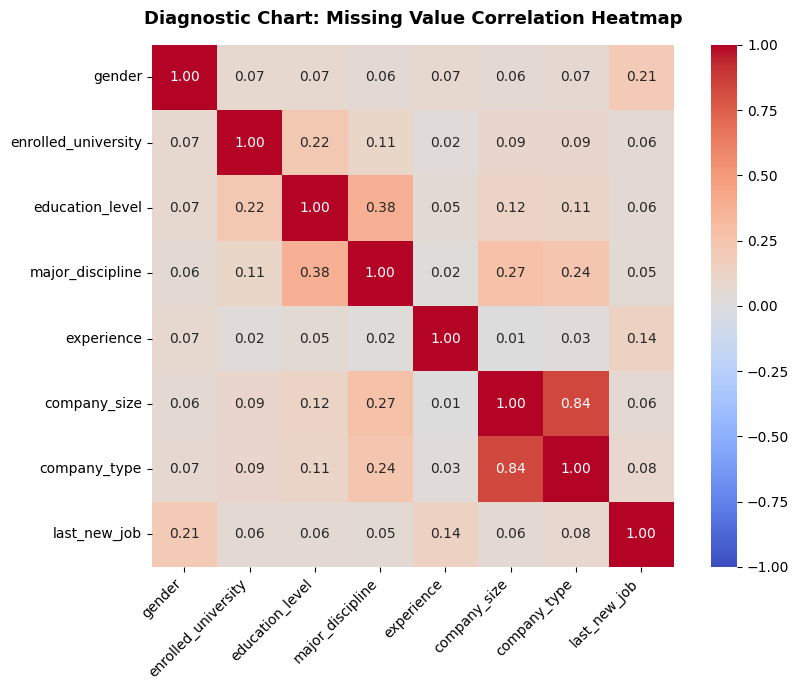

In [ ]:
cols_with_missing = df_raw.columns[df_raw.isnull().sum() > 0]

missing_corr = df_raw[cols_with_missing].isnull().corr()

# Plot Missing Value Correlation Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    missing_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    cbar=True,
    square=True
)

plt.title('Diagnostic Chart: Missing Value Correlation Heatmap', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

#### Diagnostic Findings (Diagnostic Chart: Missing Value Correlation Heatmap):
* **High Nullity Correlation (0.84):** A critical correlation of **0.84** exists between `company_size` and `company_type`, indicating that when an applicant omits one employer detail, they almost invariably omit the other. However, this statistical association alone cannot establish the underlying cause or confirm a specific missingness mechanism (such as MNAR).
* **Moderate Academic Linkage (0.38):** A secondary correlation of **0.38** occurs between `major_discipline` and `education_level`. Applicants lacking high-level degrees (e.g., high school or primary education graduates) frequently have no recorded major discipline.
* **Justification for Handling Strategy:** The high inter-correlation between missing fields shows structured patterns in non-response. Listwise deletion would remove a substantial proportion of records and may disproportionately exclude certain candidate groups. Retaining records with explicit missing-value categories helps reduce this risk, although the exact impact on subgroup representation has not been fully quantified. Flagging these columns with explicit `'Unknown'` and `'Not Disclosed'` tokens preserves these patterns without making assumptions about the missingness mechanism or forcing artificial mode imputations.

### **Diagnostic Chart (Outliers)**

Boxplot of **Training Hours** – Identifies potential outliers.

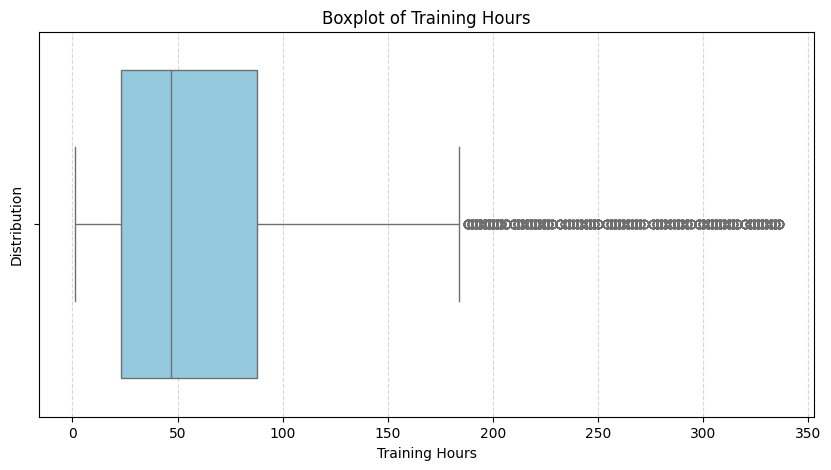

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df_raw['training_hours'],
    color='skyblue'
)

plt.title('Boxplot of Training Hours')
plt.xlabel('Training Hours')
plt.ylabel('Distribution')

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

What to observe:
- The box represents the middle 50% of the data.
- The line inside the box represents the median.
- The whiskers show the range of non-outlier observations.
- Individual points beyond the whiskers represent potential outliers.

The boxplot of training hours reveals the presence of potential outliers, as several observations extend beyond the upper whisker. This indicates that some candidates have significantly higher training hours compared to the majority of candidates. The IQR method was applied to identify these extreme values. However, the outliers were retained because they may represent genuine training participation rather than incorrect data.

### **Diagnostic Chart (Inconsistent Categories)**

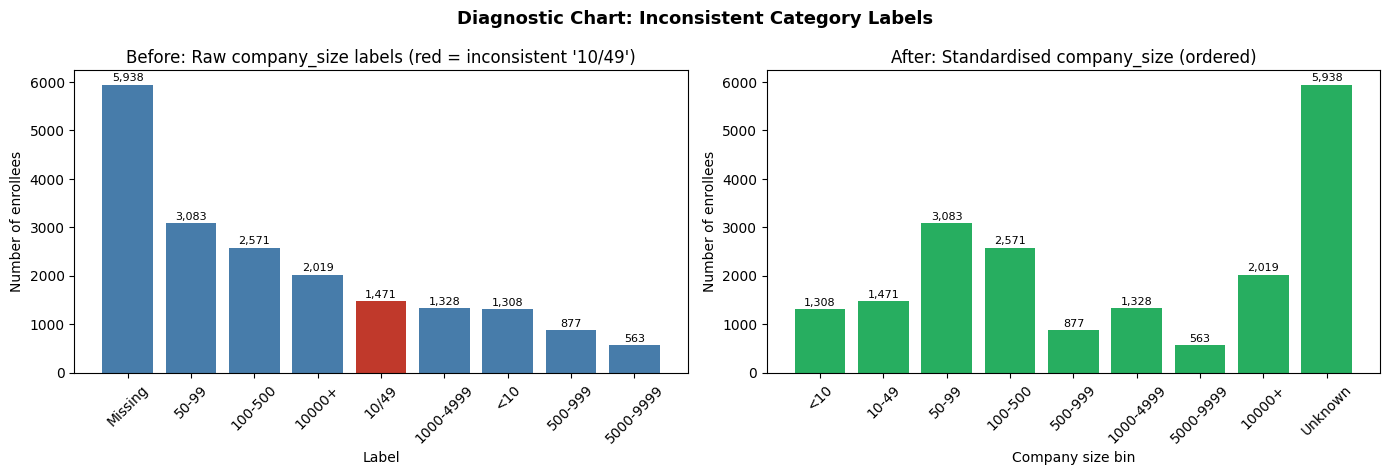

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Before: raw labels as they appear in the file
raw_counts = df_raw['company_size'].fillna('Missing').value_counts()
colors = ['#c0392b' if '/' in lbl else '#477caa' for lbl in raw_counts.index]
axes[0].bar(raw_counts.index, raw_counts.values, color=colors)
axes[0].set(title="Before: Raw company_size labels (red = inconsistent '10/49')",
            xlabel='Label', ylabel='Number of enrollees')
axes[0].tick_params(axis='x', rotation=45)

# After: standardised and ordered
std_counts = df_clean['company_size_std'].value_counts().reindex(size_order).fillna(0)
axes[1].bar(std_counts.index, std_counts.values, color='#27ae60')
axes[1].set(title='After: Standardised company_size (ordered)',
            xlabel='Company size bin', ylabel='Number of enrollees')
axes[1].tick_params(axis='x', rotation=45)

for ax in axes:
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width()/2, p.get_height() + 80,
                f'{int(p.get_height()):,}', ha='center', fontsize=8)

plt.suptitle('Diagnostic Chart: Inconsistent Category Labels', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#### Diagnostic Chart: Inconsistent Category Labels (`company_size`)

* **What it shows:** The left chart shows the raw `company_size` labels. The red bar, `10/49` (1,471 rows, 7.68%), is the only range written with a slash instead of a hyphen (e.g. `50-99`). The right chart shows the column after we fixed it and put the bins in order from smallest to largest.

* **Why it matters and how we fixed it:** Left as is, `10/49` is treated as a different category from the hyphenated `10-49` style, and it sorts out of order. We replaced `/` with `-` in a new column, `company_size_std`, and kept the original. All other bin counts stayed the same, so no data was lost.

* **Limitation:** The biggest bar in the raw data is missing values (5,938 rows, 30.99%). We labelled these `Unknown` and the right chart shows the same 5,938 rows. This is almost a third of the column, so it should be treated as its own group and not assumed to be missing at random.

## **5. Personally Identifiable Information (PII) and Bias Risks**

The dataset has no names, email addresses or phone numbers but this does not guarantee anonymity. The enrollee_id is a pseudonymous identifier while the city, demographic and career informations may together acts as quasi-identifiers. The target which is job-change intentions is also a sensitive employment related information.

| Field(s) | Risk | Risk-handling decision |
|---|---|---|
| enrollee_id | A unique record identifier that could be a linkage to other records. | Exclude from the analysis-ready data, keep the original only in access-controlled source data when needed for internal record matching. |
| gender | Personal demographic information and the missing values may show non-disclosure. | Keep the Not Disclosed as a separate audit category and it should not be inferred or fabricated. Access should be limited and avoid using it in individual-level decisions. |
| city,education_level, experience, company details | Combined attributes can represent small subgroups or increase re-identification risk. | Publish the aggregated results, suppress very small groups when sharing externally, and use access controls for record-level data. |
| target | Records individual stated intent to change jobs. | Report aggregated job-change rates rather than individual outcomes. |

Removing enrollee_id is data minimisation not complete anonymisation as the other data are still attributes that need careful handling.



In [ ]:
required_columns = {'enrollee_id', 'gender', 'target', 'city'}
assert required_columns.issubset(df_raw.columns), 'Expected HR Analytics columns are missing.'

print('Unique enrollee IDs:', df_raw['enrollee_id'].nunique())
print('Total rows:', len(df_raw))
print('Duplicate enrollee IDs:', df_raw['enrollee_id'].duplicated().sum())
print('Direct contact fields found:', [c for c in ['name', 'email', 'phone', 'address'] if c in df_raw.columns])

# Remove the unique identifier in a separate copy to avoid altering teammates' data.
df_analysis = df_clean.drop(columns=['enrollee_id'], errors='ignore').copy()
assert 'enrollee_id' not in df_analysis.columns
print('Analysis-ready shape (ID removed):', df_analysis.shape)


Unique enrollee IDs: 19158
Total rows: 19158
Duplicate enrollee IDs: 0
Direct contact fields found: []
Analysis-ready shape (ID removed): (19158, 17)


### **Sampling, representation and label imbalance**

The data represents people who enrolled in training not a random sample of all workers or all job applicants. At the same time, the findings also may not generalise to a broader labour market. The dataset also does not have enough context to decide if demographic differences is due to recruitment, recording or underlying population factors.



### **Reproducible bias and group-balance audit (train data only)**

In [ ]:
audit = df_raw[['gender', 'target']].copy()
audit['gender_group'] = audit['gender'].fillna('Not Disclosed')
audit['target'] = pd.to_numeric(audit['target'], errors='coerce')
assert audit['target'].notna().all(), 'Target labels are unexpectedly missing.'
assert audit['target'].isin([0, 1]).all(), 'Unexpected target label values.'

gender_summary = (
    audit.groupby('gender_group', dropna=False)
    .agg(records=('target', 'size'), positive_target=('target', 'sum'), job_change_rate=('target', 'mean'))
    .reset_index()
)
gender_summary['share_pct'] = (100 * gender_summary['records'] / len(audit)).round(2)
gender_summary['job_change_rate_pct'] = (100 * gender_summary['job_change_rate']).round(2)
gender_summary['positive_target'] = gender_summary['positive_target'].astype(int)

display(gender_summary[['gender_group', 'records', 'share_pct', 'positive_target', 'job_change_rate_pct']])

label_counts = audit['target'].value_counts().sort_index()
label_pct = (100 * audit['target'].value_counts(normalize=True).sort_index()).round(2)
print('\nOverall target balance:')
for label in label_counts.index:
    print(f'  target={int(label)}: {label_counts[label]:,} records ({label_pct[label]:.2f}%)')

known_gender = audit[audit['gender'].notna()]
print(f'\nGender not disclosed: {audit["gender"].isna().sum():,} '
      f'({100*audit["gender"].isna().mean():.2f}%)')
print('Shares among those who disclosed gender:')
print((100 * known_gender['gender'].value_counts(normalize=True)).round(2).to_string())


,gender_group,records,share_pct,positive_target,job_change_rate_pct
0,Female,1238,6.46,326,26.33
1,Male,13221,69.01,3012,22.78
2,Not Disclosed,4508,23.53,1389,30.81
3,Other,191,1.00,50,26.18



Overall target balance:
  target=0: 14,381 records (75.07%)
  target=1: 4,777 records (24.93%)

Gender not disclosed: 4,508 (23.53%)
Shares among those who disclosed gender:
gender
Male      90.25
Female     8.45
Other      1.30


### **Diagnostic group-balance charts**

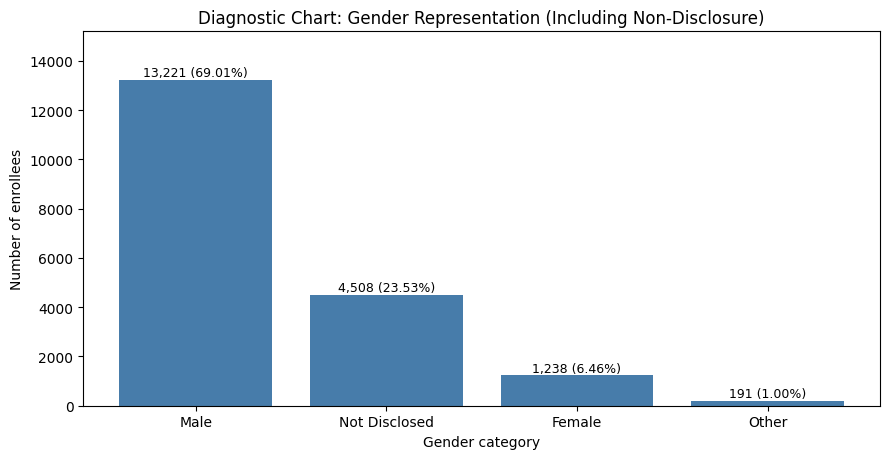

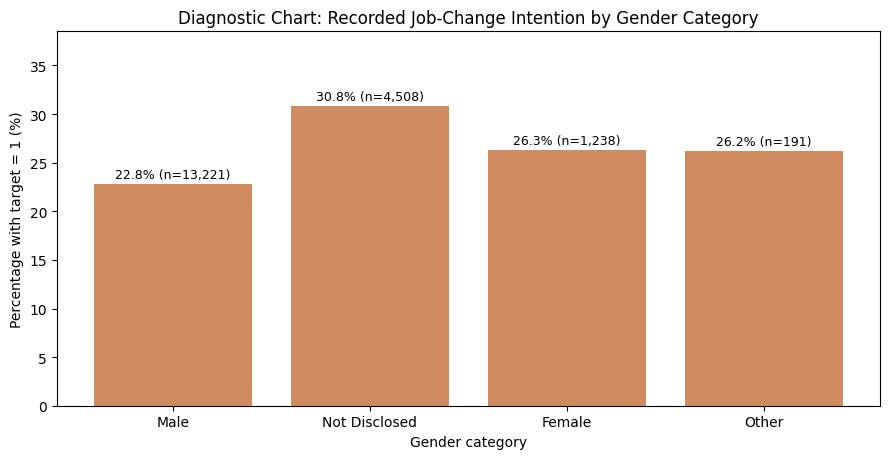

In [ ]:
# Chart 1: representation, including non-disclosure
chart_data = gender_summary.sort_values('records', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.7))
bars = ax.bar(chart_data['gender_group'], chart_data['records'], color='#477caa')
ax.set(title='Diagnostic Chart: Gender Representation (Including Non-Disclosure)',
       xlabel='Gender category', ylabel='Number of enrollees')
ax.set_ylim(0, chart_data['records'].max() * 1.15)
for bar, share in zip(bars, chart_data['share_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 150,
            f'{bar.get_height():,.0f} ({share:.2f}%)', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# Chart 2: observed target=1 rate, grouped by reported gender
fig, ax = plt.subplots(figsize=(9, 4.7))
bars = ax.bar(chart_data['gender_group'], chart_data['job_change_rate_pct'], color='#d08c60')
ax.set(title='Diagnostic Chart: Recorded Job-Change Intention by Gender Category',
       xlabel='Gender category', ylabel='Percentage with target = 1 (%)')
ax.set_ylim(0, max(chart_data['job_change_rate_pct']) * 1.25)
for bar, n in zip(bars, chart_data['records']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.6,
            f'{bar.get_height():.1f}% (n={n:,})', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
print('--- Investigating "Male" Count ---')

# 1. Count in raw dataframe
raw_gender_counts = df_raw['gender'].value_counts(dropna=False)
print('Raw Gender Counts (including NaN):')
print(raw_gender_counts)

# 2. Check if there are whitespaces or case-sensitivity issues in raw data
raw_gender_exact = df_raw['gender'].astype(str).value_counts()
print('\nRaw exact string matches (including stringified nan):')
print(raw_gender_exact)

--- Investigating "Male" Count ---
Raw Gender Counts (including NaN):
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

Raw exact string matches (including stringified nan):
gender
Male      13221
nan        4508
Female     1238
Other       191
Name: count, dtype: int64


#### Findings, bias risks and recommended safeguards
1. Unequal demographic representation: 13,221 records are labelled Male  which is 69.01% of all rows, while 1,238 are Female (6.46%) and 191 are Other (1.00%); another 4,508 (23.53%) do not report gender. Among records with a disclosed gender, approximately 90.25% are labelled Male. Therefore, group-level conclusions may be less stable for smaller groups.

2. Missing demographic information: Do not replace missing gender with Male or assume that all Not Disclosed entries belong to the same actual demographic group. The missingness category should be preserved and reported explicitly.

3. Label imbalance: target = 0 occurs in 14,381 rows (75.07%), while target = 1 occurs in 4,777 (24.93%). If a classifier is later built, accuracy alone may be misleading. Recall or precision and subgroup results can be reported as appropriate.

4. Observed differences are descriptive, not proof of unfair treatment: Recorded target = 1 rates are approximately 22.78% for Male, 26.33% for Female, 26.18% for Other, and 30.81% for Not Disclosed. These figures are neither causal estimates nor a model fairness test. Group sizes and missingness should be considered before interpreting them.

5. Potential sampling bias: Only training enrollees are covered; the data cannot establish the gender composition or job-changing behaviour of the broader candidate population. No external population benchmark is supplied.

Recommended handling:
- Remove unique IDs from analysis outputs
- report aggregate summaries
- restrict access to record-level demographic and employment details
- preserve non-disclosure
- document sample and label imbalance
- audit subgroup performance before consequential use.


## **6. Conclusion**

This HR Analytics dataset is suitable for an educational data-profiling and cleaning exercise as it contains 19,158 labelled training-enrollee records with clear missing-value patterns, categorical inconsistencies, and population imbalances. This data can be used to explore data quality and descriptive associations with stated job-change intention after cleaning and documentation. The study should not be presented as validating recruitment or employment decisions.

Missing employer and demographic details may have non-random causes that cannot be confirmed from this dataset alone. Simple mode imputation can cause uncertainty. Gender is not reported for 23.53% of records, gender and target categories are uneven and training-course enrollees may not represent the broader workforce. Removing enrollee_id lowers linkage risk but does not fully anonymise other attributes. Furthermore, aug_test.csv lacks a target column and cannot independently validate job-change rates or model predictions without labels.